# Определение возраста по фотографии

Перенос обучения ResNet50 с ImageNet, регрессия возраста, аугментация. 7 591 изображение; MAE на отложенной выборке в сохранённом прогоне — 5,8608 года.

Учебная работа НИУ ВШЭ или Яндекс Практикума; исходные формулировки заданий принадлежат авторам курса.

**Воспроизводимость:** Нужны labels.csv (file_name, real_age) и папка final_files с фотографиями из учебного набора ChaLearn. Код обучения сохранён в Markdown-блоке, как требовал GPU-тренажёр; ноутбук не запускает его автоматически. Отложенная выборка использовалась при обучении как validation.

Сохранённые результаты получены до публикации; полное обучение при подготовке репозитория не повторялось.


<div class="alert alert-info">
<font size="4"><b>Комментарий ревьюера</b></font>
    <br /> 
    <font size="3", color = "black">
<br />
    Привет, Марьяна! Спасибо, что прислала задание :) <br>Меня зовут Никита Сон и я буду проверять твой проект. Предлагаю обращаться друг к другу на ты, как это принято в Практикуме, если ты не против. Но если хочешь на Вы - не буду возражать 🙂
        
Поехали 🚀
    <br />

Мои комментарии обозначены пометкой <b>Комментарий ревьюера</b>. При внесении правок в проект, пожалуйста, не меняй и не удаляй их т.к. дальнейшая проверка будет происходить в том числе на основе того, исправлены замечания в комментариях или нет. Зато ты всегда можешь оставить свои комментарии для меня :)
    </font>
</div>

<div class="alert alert-success">
<font size="4"><b>✔️ Комментарий ревьюера</b></font>
    <br /> 
    <font size="3", color = "black">
<br />
В зелёных блоках будут позитивные комментарии
<br />
    </font>
</div>

<div class="alert alert-warning">
<font size="4"><b>⚠️ Комментарий ревьюера</b></font>
    <br /> 
    <font size="3", color = "black">
<br />
В жёлтых - некритичные замечания
    </font>
</div>

<div class="alert alert-danger">
<font size="4"><b>❌ Комментарий ревьюера</b></font>
    <br /> 
    <font size="3", color = "black">
<br /> 
В красных - важные замечания, которые надо обязательно устранить
    </font>
</div>

<div class="alert alert-info">
<font size="4">🍕<b> Комментарий ревьюера</b></font>
    <br /> 
    <font size="3", color = "black">
<br /> 
В синих с пиццей - различные нейтральные сообщения, советы на будещее и прочее.
    </font>
</div>

# Определение возраста покупателей для супермаркета «Хлеб-Соль» 

Для сетевого супермаркета «Хлеб-Соль» необходимо внедрить систему компьютерного зрения для обработки фотографий покупателей в зоне при кассе с целью определения их возраста для:
- анализа покупок и предложения товаров, которые могут заинтересовать покупателей этой возрастной группы
- контроля добросовестности кассиров при продаже алкоголя.

**Цель исследования:** построить модель, определяющую по фотографии приблизительный возраст человека. 

**Описание данных:** Набор фотографий людей формата jpg с указанием возраста: [ChaLearn Looking at People](http://chalearnlap.cvc.uab.es/dataset/26/description/)

**Ход исследования:** 
1. провести исследовательский анализ данных
2. обучить модель
3. сделать анализ по обученной модели

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50 
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D 
from tensorflow.keras.models import Sequential 
from tensorflow.keras.optimizers import Adam

In [2]:
SEED = 1234

<div class="alert alert-success">
<font size="4"><b>✔️ Комментарий ревьюера</b></font>
    <br /> 
    <font size="3", color = "black">
<br />
Задать SEED в константу - отличное решение

## Исследовательский анализ данных

In [3]:
# загрузка данных
try:
    df = pd.read_csv('/datasets/faces/labels.csv')
except:
    print('Произошла ошибка при загрузке датасета')
train_datagen = ImageDataGenerator(rescale=1./255)
train_datagen_flow = train_datagen.flow_from_dataframe(
        dataframe=df,
        directory='/datasets/faces/final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        seed=SEED)

Found 7591 validated image filenames.


<div class="alert alert-success">
<font size="4"><b>✔️ Комментарий ревьюера</b></font>
    <br /> 
    <font size="3", color = "black">
<br />
Безопасная загрузка данных - это добро

In [4]:
print(f'Размер выборки: {df.shape[0]} фотографий')

Размер выборки: 7591 фотографий


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


In [6]:
df.head()

    file_name  real_age
0  000000.jpg         4
1  000001.jpg        18
2  000002.jpg        80
3  000003.jpg        50
4  000004.jpg        17

In [7]:
df.describe()

          real_age
count  7591.000000
mean     31.201159
std      17.145060
min       1.000000
25%      20.000000
50%      29.000000
75%      41.000000
max     100.000000

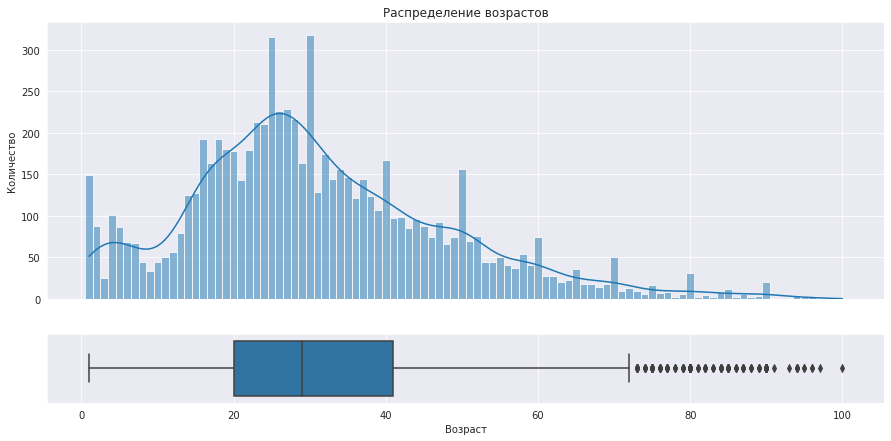

In [10]:
sns.set_style('darkgrid')

_, [axs_hist, axs_box] = plt.subplots(2, 1,
                                     figsize=(15, 7), 
                                     sharex=True,
                                     gridspec_kw=dict(height_ratios=[4,1]))
sns.histplot(data=df, x='real_age', discrete=True, kde=True, ax=axs_hist).set(title='Распределение возрастов', ylabel='Количество')
sns.boxplot(data=df, x='real_age', ax=axs_box).set(xlabel='Возраст');

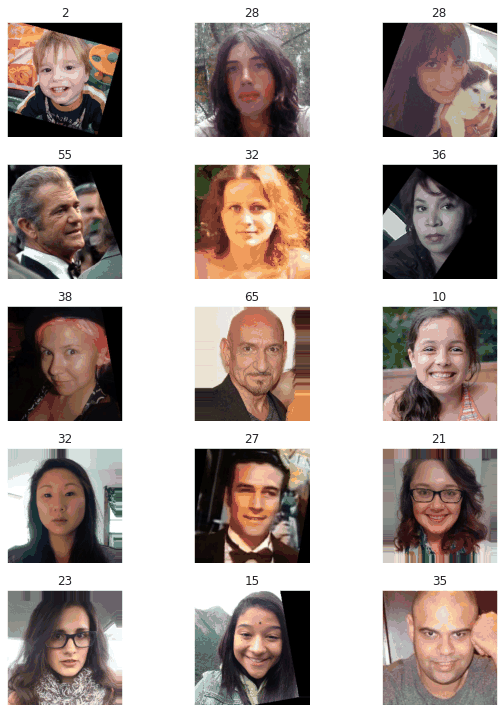

In [9]:
features, target = next(train_datagen_flow)

# выведем 15 фотографий с возрастами
fig = plt.figure(figsize=(10,10))
for i in range(15):
    fig.add_subplot(5, 3, i+1)
    plt.title(target[i]) 
    plt.imshow(features[i])
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()

<div class="alert alert-success">
<font size="4"><b>✔️ Комментарий ревьюера</b></font>
    <br /> 
    <font size="3", color = "black">
        <b></b>

Молодец, что подписала изображения указанным в таргете возрастом. Это даёт возможность оценить адекватность разметки.

**Вывод**
1. В датасете 7591 фотографий, нет пропусков
2. Возраст изображенных на фотографиях от 1 до 100, средний возраст - 31 год, медианный возраст - 29
3. Данные на гистограмме распределены нормально, основное количество возрастов в диапазоне от 20 до 40, есть выбросы после 70, есть пики на 25, 30, 40 и других кратных 10 возрастах, возможно, из-за приблизительного определения возраста. 
4. Фотографии имеют разное разрешение и качество, есть фотографии с дополнительными предметами перед или около лица (кот, очки), люди изображены с разным поворотом головы (3/4, в профиль, анфас), фотографии были сделаны под разным улгом и повернуты с дополнительным черным фоном, в целом, данные качественные и не требуют дополнительной обработки
5. Поскольку это задача регрессии и среди данных присутствуют выбросы в качестве метрики будем использовать MAE, как менее чувствительную к ним

<div class="alert alert-success">
<font size="4"><b>✔️ Комментарий ревьюера</b></font>
    <br /> 
    <font size="3", color = "black">
        <b></b>

Выводы ОК: разнообразие датасета подчёркнуто, пики на "круглых" годах подсвечены, что вообще редкость для студентов в текущем проекте.

## Обучение модели

Код в этом разделе запускается в отдельном GPU-тренажёре, поэтому оформлен не как ячейка с кодом, а как код в текстовой ячейке

```python
def load_train(path):
    df = pd.read_csv(path + 'labels.csv')
    train_datagen = ImageDataGenerator(validation_split=0.25, horizontal_flip=True, rescale=1./255)
    train_datagen_flow = train_datagen.flow_from_dataframe(
        dataframe=df,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='training',
        seed=SEED)

    return train_datagen_flow


def load_test(path):
    df = pd.read_csv(path + 'labels.csv')
    train_datagen = ImageDataGenerator(validation_split=0.25, rescale=1./255)
    test_datagen_flow = train_datagen.flow_from_dataframe(
        dataframe=df,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='validation',
        seed=SEED)

    return test_datagen_flow

def create_model(input_shape):

    backbone = ResNet50(input_shape=input_shape,
                    weights='imagenet', 
                    include_top=False)
    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(1, activation='relu'))

    optimizer = Adam(lr=0.0001)
    model.compile(optimizer=optimizer, loss='mean_squared_error',
                  metrics=['mae'])

    return model

def train_model(model, train_data, test_data, batch_size=None, epochs=10,
                steps_per_epoch=None, validation_steps=None):
    model.fit(train_data,
              validation_data=test_data,
              batch_size=batch_size, 
              epochs=epochs,
              steps_per_epoch=steps_per_epoch,
              validation_steps=validation_steps,
              verbose=2)

    return model
```

<div class="alert alert-success">
<font size="4"><b>✔️ Комментарий ревьюера</b></font>
    <br /> 
    <font size="3", color = "black">
        <b></b>

Здорово, что не только провела аугментацию, но и сделала её адекватно: многие студенты кроме горизонтального флипа делают также вертикальный, но, поскольку люди не будут смотреть в камеру так 🙃, то пользы вертикальный бы не принёс, скорее наоборот.

```python

Train for 178 steps, validate for 60 steps
Epoch 1/10
2025-10-22 21:26:26.718127: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcublas.so.10
2025-10-22 21:26:27.048185: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudnn.so.7
178/178 - 66s - loss: 248.9217 - mae: 11.1930 - val_loss: 832.2006 - val_mae: 23.8916
Epoch 2/10
178/178 - 38s - loss: 82.7196 - mae: 6.8607 - val_loss: 710.8631 - val_mae: 21.5398
Epoch 3/10
178/178 - 38s - loss: 53.6030 - mae: 5.6131 - val_loss: 467.9164 - val_mae: 16.4572
Epoch 4/10
178/178 - 38s - loss: 38.9928 - mae: 4.7395 - val_loss: 159.0515 - val_mae: 9.3418
Epoch 5/10
178/178 - 39s - loss: 27.9539 - mae: 4.0398 - val_loss: 81.7731 - val_mae: 6.6774
Epoch 6/10
178/178 - 38s - loss: 21.5543 - mae: 3.5779 - val_loss: 69.9280 - val_mae: 6.2984
Epoch 7/10
178/178 - 38s - loss: 17.7611 - mae: 3.1877 - val_loss: 67.0135 - val_mae: 6.0932
Epoch 8/10
178/178 - 38s - loss: 13.4909 - mae: 2.7936 - val_loss: 65.3162 - val_mae: 6.0794
Epoch 9/10
178/178 - 39s - loss: 11.2288 - mae: 2.5629 - val_loss: 67.1005 - val_mae: 6.0868
Epoch 10/10
178/178 - 39s - loss: 10.2300 - mae: 2.4304 - val_loss: 61.8627 - val_mae: 5.8608

60/60 - 9s - loss: 61.8627 - mae: 5.8608

```

<div class="alert alert-success">
<font size="4"><b>✔️ Комментарий ревьюера</b></font>
    <br />
    <font size="3", color = "black">
<br />    
Метрика
<img src="https://memi.klev.club/uploads/posts/2024-04/memi-klev-club-xvb2-p-memi-kot-priemlemo-16.jpg" width=300>

## Анализ обученной модели

Согласно полученным результатам погрешность при определении возраста в данной выборке 6 лет. Определение возраста клиентов требовалось для двух целей: анализа покупок и предложения товаров, которые могут заинтересовать покупателей этой возрастной группы и контроля добросовестности кассиров при продаже алкоголя.

Полученные результаты указывают на пригодность модели для маркетинговых целей, так как ошибка в 6 лет при отнесении человека к определенной возрастной категории (дети, подростки, молодые люди, люди среднего возраста, пожилые люди) с возможным разделением по 10 лет не будет критичной. 

Однако модель не подойдет для второй цели - для контроля добросовестности кассиров требуется большая точность. Тем не менее, можно сократить количество материала, которое требует проверки и контроля со стороны человека. Модель может автоматизировать выделение клиентов, которые соответствуют группе молодые люди-подростки, и уже меньшему количеству данных будет необходима дополнительная проверка. 

<div class="alert alert-success">
<font size="4"><b>✔️ Комментарий ревьюера</b></font>
    <br />
    <font size="3", color = "black">
<br />    
Когда студенты пишут, что "модель не подойдёт для второй" цели, я пишу весьма развёрнутый комментарий на тему того, что ни одна модель кассира заменить не может, ведь если сегодня покупателю 17, но завтра у него День рождения, то сегодня продать алкоголь нельзя, а завтра - можно, следовательно, нужна идеальная модель с предсказаниями точными аж до 1 дня, а такое, естественно, нереально.

Но ты - тот редкий случай студента, которая в своих суждениях пошла дальше того что "не пригодно", поняла, что если принять граничные условия нашего проекта, то модель всё равно может принести пользу. А в каком виде - тут уже возможны разные варианты - можно обязать кассиров проверять документы у всех, у кого модель считает возраст достаточно низким, либо дополнительно проверять тех кассиров, которые слишком часто отпускают слишком молодым по мнению модели людям.

В общем, твой анализ обученной модели меня дико порадовал. Не побоюсь этих слов, ты мыслишь как настоящий data scientist, и это очень круто 🙂

## Вывод

- Построенная модель частично выполняет поставленную цель и требует большей точности: погрешность определения возраста 6 лет слишком велика для автоматизации процесса контроля добросовестности продажи алкоголя. Возможным решением сложности может быть расширение обучающей выборки, особенно примеров с детьми, подростками и молодыми людьми, относящимися к проверяемым группам. 
- Набор данных, на которых обучена модель состоит из 7591 фотографий, которым соответствуют информация о возрасте человека. Большая часть фотографий предствляет людей от 20 до 40 лет, изначальный датасет не требовал дополнительной коррекции. 
- При обучении модели была применена аугментация - горизонтальное отражение, которое не искажает возраст. Размер батча был выбран как оптимальный для стабильности модели и скорости обучения. Была использована предобученная на ImageNet модель. Для данной задачи регрессии был нужен всего один нейрон, который возвращает число предсказание. 

<div class="alert alert-success">
<font size="4"><b>✔️ Комментарий ревьюера</b></font>
    <br />
    <font size="3", color = "black">
<br />    
Подведём итоги.

Ну, даже не знаю что сказать. Проект, конечно, достаточно небольшой и не сложный, но регулярно мне приходится студентам при проверке оставлять 1-2 жёлтых комментария. Тебе я не нашёл за что. Если это не лучший проект по комп. зрению, что я проверял, то уж точно один из них. Поэтому отправлять на доработку его - кощунство. Если у тебя будут какие-то вопросы по ревью - обращайся через куратора, я отвечу. А так, мне сейчас остаётся только лишь пожелать тебе успехов с оставшимися заданиями курса!